# 从Numpy到Pytorch: 以线性回归为例

# 一、Numpy实现

In [12]:
import numpy as np

import torch
import torch.optim as optim
import torch.nn as nn
from torchviz import make_dot
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')


## 读取数据

### 下载整理数据集

- 这里采用简单的合成数据的方法
- 线性回归模型

$$
\Large y = b + w x + \epsilon
$$
其中，b 表示偏置，也就是截距；w 表示权重，也就是斜率；$\epsilon$ 表示随机噪声。

In [3]:
# 我把真实的参数设置为：
true_b = 1
true_w = 2
# 也就是说，我们希望最终训练出来的模型参数能够接近：b=1 w=2
N = 100 # 生成100条数据

# 数据生成
np.random.seed(42) #为了固定随机数种子，让每次运行得到的数据基本一致，方便实验复现。
# 随机生成 100 个 x，并加入一定的随机噪声，得到对应的 y。
x = np.random.rand(N, 1)
epsilon = (.1 * np.random.randn(N, 1))
y = true_b + true_w * x + epsilon

### 数据划分
- 对 100 条数据进行随机打乱，其中前 80% 作为训练集，剩下的 20% 作为验证集。
- 训练集负责让模型学习参数，验证集可以用于观察模型对没有直接参与训练的数据的拟合效果。

In [4]:
# Shuffles the indices
idx = np.arange(N)
np.random.shuffle(idx)

# Uses first 80 random indices for train
train_idx = idx[:int(N*.8)]
# Uses the remaining indices for validation
val_idx = idx[int(N*.8):]

# Generates train and validation sets
x_train, y_train = x[train_idx], y[train_idx]
x_val, y_val = x[val_idx], y[val_idx]

### 数据可视化
- 接下来代码将训练集和验证集分别进行了散点图可视化。
- 从图中可以看到，虽然数据存在一定噪声，但是总体上呈现比较明显的线性关系，因此使用线性回归模型是合理的。

In [1]:
def figure1(x_train, y_train, x_val, y_val):
    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    
    ax[0].scatter(x_train, y_train)
    ax[0].set_xlabel('x')
    ax[0].set_ylabel('y')
    ax[0].set_ylim([0, 3.1])
    ax[0].set_title('Generated Data - Train')

    ax[1].scatter(x_val, y_val, c='r')
    ax[1].set_xlabel('x')
    ax[1].set_ylabel('y')
    ax[1].set_ylim([0, 3.1])
    ax[1].set_title('Generated Data - Validation')
    fig.tight_layout()
    
    return fig, ax

(<Figure size 1200x600 with 2 Axes>,
 array([<Axes: title={'center': 'Generated Data - Train'}, xlabel='x', ylabel='y'>,
        <Axes: title={'center': 'Generated Data - Validation'}, xlabel='x', ylabel='y'>],
       dtype=object))

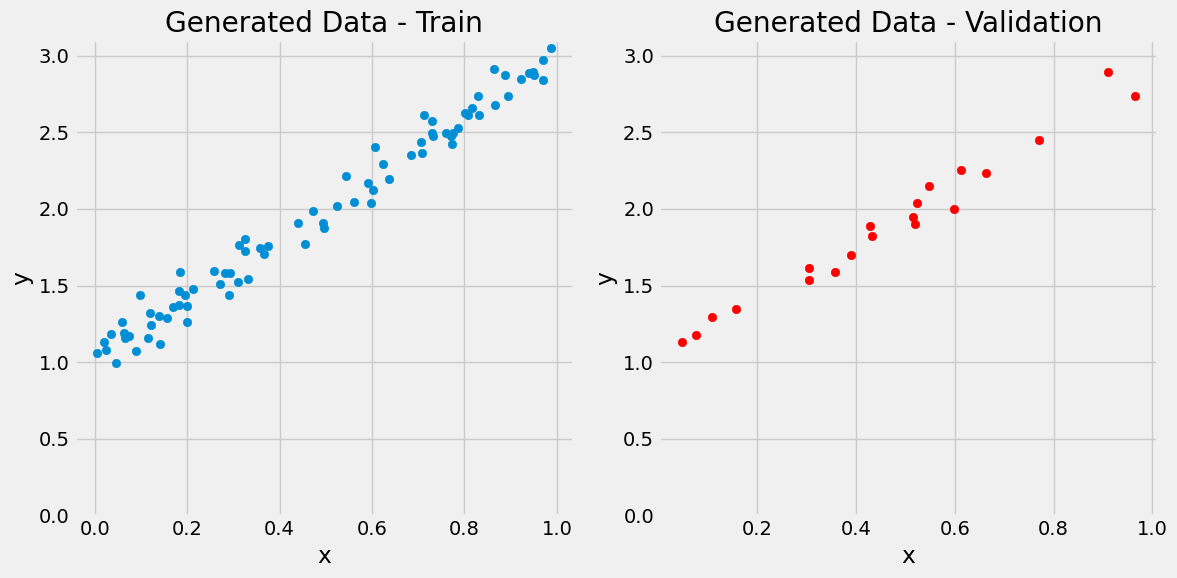

In [7]:
figure1(x_train, y_train, x_val, y_val)

# 前馈计算

In [6]:
np.random.seed(42)
# 一开始我们并不知道正确的 b 和 w，所以先随机初始化
b = np.random.randn(1)
w = np.random.randn(1)
print(b, w) # 当前初始值和真实值b=1，w=2差距还是很大的

# 接下来就是线性回归
yhat = b + w * x_train # 这一步就是神经网络中经常说的 forward pass，也就是前向传播。


[0.49671415] [-0.1382643]


## 计算损失
- 有了预测结果之后，需要判断预测结果到底好不好。
- 这里使用的是均方误差，也就是 MSE。

In [7]:
# Step 2 - Computing the loss
# We are using ALL data points, so this is BATCH gradient
# descent. How wrong is our model? That's the error!
error = (yhat - y_train)

# It is a regression, so it computes mean squared error (MSE)
loss = (error ** 2).mean()

print(loss) # 这个值比较大，因为一开始的参数距离真实参数还比较远。因此接下来的目标就是：不断修改 b 和 w，让 loss 尽可能下降。

2.7421577700550976


## 更新参数
- 整个训练过程最核心的一步：梯度下降。

In [8]:
# 计算梯度：
b_grad = 2 * error.mean()
w_grad = 2 * (x_train * error).mean()
print(b_grad, w_grad) # 这两个值分别就是损失函数对于参数 b 和 w 的偏导数。

# 设置学习率
lr = 0.1
print(b, w)

# 按照梯度下降公式更新参数，梯度告诉我们损失增大的方向，因此沿着梯度的反方向更新参数，就能够让损失逐渐减小。
b = b - lr * b_grad
w = w - lr * w_grad

print(b, w) # 经过一次更新后，可以看到 b 和 w 已经开始向正确方向移动。

-3.044811379650508 -1.8337537171510832
[0.49671415] [-0.1382643]
[0.80119529] [0.04511107]


## 训练模型
- 前面实际上已经完成了训练的一次迭代。
- 接下来只需要把上面的代码组织起来，把整个过程放进循环中重复执行。

In [10]:
# Step 0 - Initializes parameters "b" and "w" randomly
np.random.seed(42)
b = np.random.randn(1)
w = np.random.randn(1)

print(b, w)

# Sets learning rate - this is "eta" ~ the "n"-like Greek letter
lr = 0.1
# 训练1000个epoch
n_epochs = 1000 

for epoch in range(n_epochs):
    # Step 1 - 前向传播
    yhat = b + w * x_train
    
    # Step 2 - 计算损失
    # We are using ALL data points, so this is BATCH gradient
    # descent. How wrong is our model? That's the error!   
    error = (yhat - y_train)
    # It is a regression, so it computes mean squared error (MSE)
    loss = (error ** 2).mean()
    
    # Step 3 - 计算梯度
    b_grad = 2 * error.mean()
    w_grad = 2 * (x_train * error).mean()
    
    # Step 4 - 根据梯度和学习速率更新参数
    b = b - lr * b_grad
    w = w - lr * w_grad
    if epoch % 100 == 0:
        print(epoch, b, w)

print(b, w) # 训练结束以后得到：b ≈ 1.0235 w ≈ 1.9690
# 我们一开始设置的真实参数是：b = 1 w = 2，可以看到结果已经非常接近。
# 为什么不完全相等？

[0.49671415] [-0.1382643]
0 [0.80119529] [0.04511107]
100 [1.18361791] [1.65574005]
200 [1.05847344] [1.90061136]
300 [1.03116391] [1.95404818]
400 [1.02520431] [1.96570938]
500 [1.02390378] [1.96825413]
600 [1.02361998] [1.96880946]
700 [1.02355804] [1.96893064]
800 [1.02354453] [1.96895709]
900 [1.02354158] [1.96896286]
[1.02354094] [1.96896411]


# 二、PyTorch实现

## Tensor：张量

可以用来创建不同维度的数据

- 标量：单个数字，零维
- 向量：一维
- 矩阵：二维
- 张量：三维及以上维度，有时也将向量和矩阵也称作张量

In [11]:
scalar = torch.tensor(3.14159)
vector = torch.tensor([1, 2, 3])
matrix = torch.ones((2, 3), dtype=torch.float)
tensor = torch.randn((2, 3, 4, 2), dtype=torch.float)

print(scalar)
print(vector)
print(matrix)
print(tensor)

tensor(3.1416)
tensor([1, 2, 3])
tensor([[1., 1., 1.],
        [1., 1., 1.]])
tensor([[[[-0.2491, -0.6219],
          [-1.2577,  0.8707],
          [ 1.0327, -1.6837],
          [ 1.0614,  1.6250]],

         [[ 0.1292, -0.1035],
          [ 0.7644, -0.9307],
          [ 0.6304,  0.7856],
          [-0.7937, -1.1946]],

         [[-0.5710,  1.6609],
          [ 0.9058,  2.8312],
          [ 0.0467, -1.1697],
          [-1.0044,  0.5149]]],


        [[[-0.6150,  1.2139],
          [ 0.2669, -0.5031],
          [ 1.9452, -0.2086],
          [ 0.3365,  0.1637]],

         [[ 0.3628, -0.7774],
          [ 0.8287,  0.0045],
          [-0.2519,  1.3061],
          [-0.3149,  2.2180]],

         [[ 1.3095,  1.1083],
          [ 1.6436,  0.4899],
          [ 1.2377,  0.1411],
          [ 2.4961,  0.4172]]]])


形状：在深度学习中，经常出现模型报错，其实很多时候就是因为 Tensor 的形状不匹配。因此检查 shape 是我们调试神经网络时非常常用的方法。
- size()方法
- shape属性
- 标量的形状为“空”

In [17]:
print(tensor.size(), tensor.shape)

torch.Size([2, 3, 4]) torch.Size([2, 3, 4])


In [19]:
print(scalar.size(), scalar.shape)

torch.Size([]) torch.Size([])


改变形状
- view()方法不会创建新的tensor，不会改变张量的存储地址，只更改meta信息
- reshape()可能不会创建新的tensor（连续性）；也可能创建新的tensor（不连续）
- - .t()等操作会让tensor失去连续性
- - reshape() = contiguous() + view()

In [18]:
# 只是改变了 Tensor 的观察形式。
same_matrix = matrix.view(1, 6)
# 所以如果修改一个元素：
same_matrix[0, 1] = 2.
# 原来的 matrix 也会发生变化。
print(matrix)
print(same_matrix)

tensor([[1., 2., 1.],
        [1., 1., 1.]])
tensor([[1., 2., 1., 1., 1., 1.]])


复制tensor
- 如果希望真正得到一个独立的数据副本，一般使用clone()
- 结合detach()可以让复制获得的新tensor彻底摆脱之前的tensor所在的计算图

In [20]:
# Lets follow PyTorch's suggestion and use "clone" method
another_matrix = matrix.view(1, 6).clone().detach()
# Again, if we change one of its elements...
another_matrix[0, 1] = 4.
# The original tensor (matrix) is left untouched!
print(matrix)
print(another_matrix)

tensor([[1., 2., 1.],
        [1., 1., 1.]])
tensor([[1., 4., 1., 1., 1., 1.]])


## 读取数据

### Numpy array和Pytorch tensor的转换

Numpy array转Pytorch tensor
- as_tensor()和from_numpy()方法，与numpy array共享底层数据：改变array->改变tensor
- tensor()方法则是复制数据

In [20]:
x_train_tensor = torch.as_tensor(x_train)
x_train.dtype, x_train_tensor.dtype

(dtype('float64'), torch.float64)

In [21]:
float_tensor = x_train_tensor.float()
float_tensor.dtype

torch.float32

In [25]:
dummy_array = np.array([1, 2, 3])
dummy_tensor = torch.as_tensor(dummy_array)
# 修改numpy array
dummy_array[1] = 0
# Tensor也会变
print(dummy_tensor)

tensor([1, 0, 3])


Pytorch tensor转Numpy array
- numpy()方法

In [24]:
dummy_tensor.numpy()

array([1, 0, 3])

### GPU Tensor

- 检查是否存在cuda设备
- to(device) 方法就可以将tensor转移到设备device上

In [28]:
device = 'cuda' if torch.cuda.is_available() else 'cpu' # 先判断 CUDA 是否可用
device

'cuda'

In [29]:
n_cudas = torch.cuda.device_count()
for i in range(n_cudas):
    print(torch.cuda.get_device_name(i))

NVIDIA GeForce RTX 3090
NVIDIA GeForce RTX 3090
NVIDIA GeForce RTX 3090
NVIDIA GeForce RTX 3090
NVIDIA GeForce RTX 3090
NVIDIA GeForce RTX 3090


In [27]:
gpu_tensor = torch.as_tensor(x_train).to(device)
gpu_tensor[0]

tensor([0.7713], dtype=torch.float64)

将数据集tensor转移到gpu设备上

In [30]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Our data was in Numpy arrays, but we need to transform them 
# into PyTorch's Tensors and then we send them to the 
# chosen device
x_train_tensor = torch.as_tensor(x_train).float().to(device)
y_train_tensor = torch.as_tensor(y_train).float().to(device)

In [31]:
# Here we can see the difference - notice that .type() is more
# useful since it also tells us WHERE the tensor is (device)
print(type(x_train), type(x_train_tensor), x_train_tensor.type())

<class 'numpy.ndarray'> <class 'torch.Tensor'> torch.cuda.FloatTensor


numpy无法处理gpu tensor：因此如果想把 GPU Tensor 转回 NumPy，需要先：tensor.cpu() 再：.numpy()

In [32]:
back_to_numpy = x_train_tensor.numpy()

TypeError: can't convert cuda:0 device type tensor to numpy. Use Tensor.cpu() to copy the tensor to host memory first.

In [34]:
back_to_numpy = x_train_tensor.cpu().numpy()

## 前馈计算

- 初始化参数时，需要指定requires_grad为True，代表该参数需要计算梯度
- - 当神经网络有几百万甚至几十亿个参数时，不可能人工计算所有梯度
  - PyTorch 可以自动完成这个过程
- 注意观察相同种子时，cpu和gpu的随机初始化结果的异同

In [36]:
# cpu版本
torch.manual_seed(42)
b = torch.randn(1, requires_grad=True, dtype=torch.float)
w = torch.randn(1, requires_grad=True, dtype=torch.float)
print(b, w)

tensor([0.3367], requires_grad=True) tensor([0.1288], requires_grad=True)


In [38]:
# gpu版本1
torch.manual_seed(42)
b = torch.randn(1, requires_grad=True, dtype=torch.float).to(device)
w = torch.randn(1, requires_grad=True, dtype=torch.float).to(device)
print(b, w)

tensor([0.3367], device='cuda:0', grad_fn=<ToCopyBackward0>) tensor([0.1288], device='cuda:0', grad_fn=<ToCopyBackward0>)


In [39]:
# gpu版本2，调用requires_grad_()方法
# Pytorch中以下划线结尾的方法都会原地修改
torch.manual_seed(42)
b = torch.randn(1, dtype=torch.float).to(device)
w = torch.randn(1, dtype=torch.float).to(device)
b.requires_grad_()
w.requires_grad_()
print(b, w)

tensor([0.3367], device='cuda:0', requires_grad=True) tensor([0.1288], device='cuda:0', requires_grad=True)


In [40]:
# gpu版本3：推荐写法，创建的时候直接将tensor分配给设备
torch.manual_seed(42)
b = torch.randn(1, requires_grad=True, \
                dtype=torch.float, device=device)
w = torch.randn(1, requires_grad=True, \
                dtype=torch.float, device=device)
print(b, w)

tensor([0.1940], device='cuda:0', requires_grad=True) tensor([0.1391], device='cuda:0', requires_grad=True)


In [51]:
# Step 1 - 前向传播
yhat = b + w * x_train_tensor

# Step 2 - 计算 MSE loss
# We are using ALL data points, so this is BATCH gradient descent
# How wrong is our model? That's the error! 
error = (yhat - y_train_tensor)
# It is a regression, so it computes mean squared error (MSE)
loss = (error ** 2).mean()

## 更新参数
计算梯度

In [52]:
# b_grad = 2 * error.mean()
# w_grad = 2 * (x_tensor * error).mean()
loss.backward() # PyTorch 会根据计算图和链式法则自动进行反向传播。

print(error.requires_grad, yhat.requires_grad, \
      b.requires_grad, w.requires_grad)
print(y_train_tensor.requires_grad, x_train_tensor.requires_grad)

True True True True
False False


In [53]:
print(b.grad, w.grad)

tensor([-10.1642], device='cuda:0') tensor([-5.8317], device='cuda:0')


梯度默认是累积的，需要归零（初学者非常容易犯的错误）

In [54]:
# This code will be placed *after* Step 4
# (updating the parameters)
b.grad.zero_(), w.grad.zero_()

(tensor([0.], device='cuda:0'), tensor([0.], device='cuda:0'))

## 训练模型

- 把上面的代码组织起来
- no_grad防止更新也被计算梯度

In [55]:
# Sets learning rate - this is "eta" ~ the "n"-like Greek letter
lr = 0.1

# Step 0 - Initializes parameters "b" and "w" randomly
torch.manual_seed(42)
b = torch.randn(1, requires_grad=True, \
                dtype=torch.float, device=device)
w = torch.randn(1, requires_grad=True, \
                dtype=torch.float, device=device)

# Defines number of epochs
n_epochs = 1000

for epoch in range(n_epochs):
    # 2. 前馈计算
    yhat = b + w * x_train_tensor
    # 3. 计算损失
    error = (yhat - y_train_tensor)
    loss = (error ** 2).mean()
    # 4. 更新参数
    loss.backward()
    with torch.no_grad():
        b -= lr * b.grad
        w -= lr * w.grad
    
    # PyTorch is "clingy" to its computed gradients, we
    # need to tell it to let it go...
    b.grad.zero_()
    w.grad.zero_()
    
print(b, w)

tensor([1.0235], device='cuda:0', requires_grad=True) tensor([1.9690], device='cuda:0', requires_grad=True)


# 三、进一步优化代码

## 优化1：使用预定义的优化器

- 显示计算梯度、手动更新参数的方式的问题？

In [56]:
# Defines a SGD optimizer to update the parameters
optimizer = optim.SGD([b, w], lr=lr)

/root/miniconda3/envs/deepfashion/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [58]:
# Sets learning rate - this is "eta" ~ the "n"-like Greek letter
lr = 0.1

# Step 0 - Initializes parameters "b" and "w" randomly
torch.manual_seed(42)
b = torch.randn(1, requires_grad=True, \
                dtype=torch.float, device=device)
w = torch.randn(1, requires_grad=True, \
                dtype=torch.float, device=device)

# 定义优化器
optimizer = optim.SGD([b, w], lr=lr)

# Defines number of epochs
n_epochs = 1000

for epoch in range(n_epochs):
    # 2. 前馈计算
    yhat = b + w * x_train_tensor
    
    # 3. 计算损失 
    error = (yhat - y_train_tensor)
    loss = (error ** 2).mean()

    # 4. 更新参数
    loss.backward()
    # with torch.no_grad():
    #     b -= lr * b.grad
    #     w -= lr * w.grad
    optimizer.step()
    
    # 所有参数梯度归零
    # b.grad.zero_()
    # w.grad.zero_()
    optimizer.zero_grad()
    
print(b, w)

tensor([1.0235], device='cuda:0', requires_grad=True) tensor([1.9690], device='cuda:0', requires_grad=True)


## 优化2：使用预定义的损失函数

In [47]:
# Defines a MSE loss function
loss_fn = nn.MSELoss(reduction='mean')
loss_fn

MSELoss()

In [48]:
# This is a random example to illustrate the loss function
predictions = torch.tensor([0.5, 1.0])
labels = torch.tensor([2.0, 1.3])
loss_fn(predictions, labels)

tensor(1.1700)

将前面的代码组织起来

In [59]:
# Sets learning rate - this is "eta" ~ the "n"-like
# Greek letter
lr = 0.1

# Step 0 - Initializes parameters "b" and "w" randomly
torch.manual_seed(42)
b = torch.randn(1, requires_grad=True, \
                dtype=torch.float, device=device)
w = torch.randn(1, requires_grad=True, \
                dtype=torch.float, device=device)

# Defines a SGD optimizer to update the parameters
optimizer = optim.SGD([b, w], lr=lr)

# Defines a MSE loss function
loss_fn = nn.MSELoss(reduction='mean')

# Defines number of epochs
n_epochs = 1000

for epoch in range(n_epochs):
    # 2. 前馈计算
    yhat = b + w * x_train_tensor
    
    # 3. 计算损失 
    loss = loss_fn(yhat, y_train_tensor)

    # 4. 更新参数
    loss.backward()
    optimizer.step()
    optimizer.zero_grad()
    
print(b, w)

tensor([1.0235], device='cuda:0', requires_grad=True) tensor([1.9690], device='cuda:0', requires_grad=True)


在cpu中使用loss

In [60]:
loss

tensor(0.0080, device='cuda:0', grad_fn=<MseLossBackward0>)

In [61]:
loss.cpu().numpy()

RuntimeError: Can't call numpy() on Tensor that requires grad. Use tensor.detach().numpy() instead.

因为loss是要计算梯度的，因此和普通的tensor不同，这里需要先调用detach()方法

In [52]:
loss.detach().cpu().numpy()

array(0.00804466, dtype=float32)

In [53]:
print(loss.item(), loss.tolist()) #获取标量数值最方便的做法

0.008044655434787273 0.008044655434787273


## 优化3：定义模型类

继承nn.Module类：PyTorch 神经网络的标准写法

In [65]:
class ManualLinearRegression(nn.Module):
    def __init__(self): # 定义模型的组成部分
        super().__init__() #不要忘了执行父类初始化方法
        # To make "b" and "w" real parameters of the model,
        # we need to wrap them with nn.Parameter
        self.b = nn.Parameter(torch.randn(1,
                                          requires_grad=True, 
                                          dtype=torch.float))
        self.w = nn.Parameter(torch.randn(1, 
                                          requires_grad=True,
                                          dtype=torch.float))
        
    def forward(self, x): # 前馈计算
        # Computes the outputs / predictions
        return self.b + self.w * x

parameters()方法可以打印模型参数

In [55]:
torch.manual_seed(42)
# Creates a "dummy" instance of our ManualLinearRegression model
dummy = ManualLinearRegression()
y = dummy(train_x)
list(dummy.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True), Parameter containing:
 tensor([0.1288], requires_grad=True)]

state_dict()方法可以打印参数的值

In [56]:
dummy.state_dict()

OrderedDict([('b', tensor([0.3367])), ('w', tensor([0.1288]))])

优化器也有state_dict()方法

In [67]:
optimizer.state_dict()

{'state': {0: {'momentum_buffer': None}, 1: {'momentum_buffer': None}},
 'param_groups': [{'lr': 0.1,
   'momentum': 0,
   'dampening': 0,
   'weight_decay': 0,
   'nesterov': False,
   'maximize': False,
   'foreach': None,
   'differentiable': False,
   'fused': None,
   'params': [0, 1]}]}

模型同样可以用to(device)方法移动到设备device上

In [58]:
torch.manual_seed(42)
# Creates a "dummy" instance of our ManualLinearRegression model
# and sends it to the device
dummy = ManualLinearRegression().to(device)

将前面的代码组织起来

In [ ]:
# Sets learning rate - this is "eta" ~ the "n"-like
# Greek letter
lr = 0.1

# Step 0 - Initializes parameters "b" and "w" randomly
torch.manual_seed(42)
# Now we can create a model and send it at once to the device
model = ManualLinearRegression().to(device)

# Defines a SGD optimizer to update the parameters 
# (now retrieved directly from the model)
optimizer = optim.SGD(model.parameters(), lr=lr)

# Defines a MSE loss function
loss_fn = nn.MSELoss(reduction='mean')

# Defines number of epochs
n_epochs = 1000

for epoch in range(n_epochs):
    model.train() # 有些模型的训练和测试阶段的前馈过程不一样

    # 2. 前馈计算
    yhat = model(x_train_tensor)
    
    # 3. 计算损失 
    loss = loss_fn(yhat, y_train_tensor)

    # 4. 更新参数
    loss.backward()
    optimizer.step()
    optimizer.zero_grad()

    
# We can also inspect its parameters using its state_dict
print(model.state_dict())

## 优化4：调用预定义模型

In [61]:
linear = nn.Linear(1, 1)
linear

Linear(in_features=1, out_features=1, bias=True)

In [62]:
linear.state_dict()

OrderedDict([('weight', tensor([[-0.2191]])), ('bias', tensor([0.2018]))])

模型类的写法更简单了

In [69]:
class MyLinearRegression(nn.Module):
    def __init__(self):
        super().__init__()
        # Instead of our custom parameters, we use a Linear model
        # with single input and single output
        self.model = nn.Linear(1, 1)
                
    def forward(self, x):
        # Now it only takes a call
        return self.model(x)

In [70]:
torch.manual_seed(42)
dummy = MyLinearRegression().to(device)
list(dummy.parameters())

[Parameter containing:
 tensor([[0.7645]], device='cuda:0', requires_grad=True),
 Parameter containing:
 tensor([0.8300], device='cuda:0', requires_grad=True)]

In [71]:
dummy.state_dict()

OrderedDict([('linear.weight', tensor([[0.7645]], device='cuda:0')),
             ('linear.bias', tensor([0.8300], device='cuda:0'))])

## 进阶使用序列模型构建多层网络

nn.Sequential模型

In [67]:
torch.manual_seed(42)
# Alternatively, you can use a Sequential model
model = nn.Sequential(nn.Linear(1, 1)).to(device)

model.state_dict()

OrderedDict([('0.weight', tensor([[0.7645]], device='cuda:0')),
             ('0.bias', tensor([0.8300], device='cuda:0'))])

多层网络模型

In [68]:
torch.manual_seed(42)
# Building the model from the figure above
model = nn.Sequential(nn.Linear(3, 5), nn.Linear(5, 1)).to(device)

model.state_dict()

OrderedDict([('0.weight', tensor([[ 0.4414,  0.4792, -0.1353],
                      [ 0.5304, -0.1265,  0.1165],
                      [-0.2811,  0.3391,  0.5090],
                      [-0.4236,  0.5018,  0.1081],
                      [ 0.4266,  0.0782,  0.2784]], device='cuda:0')),
             ('0.bias',
              tensor([-0.0815,  0.4451,  0.0853, -0.2695,  0.1472], device='cuda:0')),
             ('1.weight',
              tensor([[-0.2060, -0.0524, -0.1816,  0.2967, -0.3530]], device='cuda:0')),
             ('1.bias', tensor([-0.2062], device='cuda:0'))])

In [69]:
torch.manual_seed(42)
# Building the model from the figure above
model = nn.Sequential()
model.add_module('layer1', nn.Linear(3, 5))
model.add_module('layer2', nn.Linear(5, 1))
model.to(device)

Sequential(
  (layer1): Linear(in_features=3, out_features=5, bias=True)
  (layer2): Linear(in_features=5, out_features=1, bias=True)
)